# 14  -  Trigger Summary

Cross-trigger comparison: return period and storm activation list for
the Philippines AA Storms programme.

| Trigger | Notebook | Method |
|---------|----------|--------|
| **Readiness** | 11.1 | CMA forecast ≥ 177 kph (1-min) issued 4–7 days before qualifying landfall |
| **Action** | 12.1 | Ensemble hindcast — probability of exceeding damage threshold |
| **Observational (wind)** | 13 | 64-kt wind footprint × population exposed |
| **Observational (rainfall)** | 13.1 | CHIRPS-GEFS 3-day rainfall ≥ threshold, issued 1 day before landfall |

In [12]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ocha_stratus as stratus
from IPython.display import display
from src.constants import CHD_GREEN

plt.rcParams.update({"font.family": "sans-serif"})

In [13]:
# ── Shared ─────────────────────────────────────────────────────────────────────
CONTAINER      = "projects"
STAGE          = "dev"
PREFIX         = "pa-aa-phl-storms/processed/"
TARGET_REGIONS = ["PH02", "PH03", "PH05", "PH08"]
TARGET_NAMES   = ["Region II", "Region III", "Region V", "Region VIII"]
TARGET_RP      = 3      # desired return period (yr)

# ── Readiness trigger (CMA forecast, 2004-2025) ────────────────────────────────
READ_KPH_1MIN  = 177
READ_START     = 2004
READ_END       = 2025
READ_YEARS     = READ_END - READ_START + 1    # 22

# ── Action trigger (ensemble hindcast, 2006-2024) — 5-level, winner-takes-all ──
# Design: PROBS = [0.95, 0.80, 0.70, 0.60, 0.50]; storm activates at lowest level met.
# 6 activated storm-seasons: Melor 2009, Haiyan 2013, Man-yi 2018,
#   Goni 2020 (50%), Molave 2020 (95%), Rai 2021 → RP 3.33yr.
# NOTE: action_ensemble.parquet may be stale. Re-run notebook 12.1 to regenerate.
ACTION_RECORD_YEARS = 19

# ── Observational (wind) trigger: 64-kt footprint × population exposed ─────────
# Threshold calibrated to RP ≥ 3yr in the combined (action OR wind OR rain) trigger.
# Sweep over 5 760 combinations showed wind ≥ 3M contributes no new seasons beyond
# action (same 6 seasons); kept at 3M to match the optimised design.
OBS_WIND_POP_THR = 3_000_000
OBS_WIND_START   = 2006
OBS_WIND_END     = 2024
OBS_WIND_YEARS   = OBS_WIND_END - OBS_WIND_START + 1   # 19

# ── Observational (rainfall) trigger: CHIRPS-GEFS 3-day at lead 1 ──────────────
# 350 mm gives RP 12yr standalone (2009 and 2014 only); in the union it adds
# 2014 (Hagupit/Ruby, 3.85M affected) which action alone cannot reach.
# Minimum safe threshold is 325mm (Trami 2024 peaked at 322mm CHIRPS-GEFS lead-1).
OBS_RAIN_MM    = 350
OBS_RAIN_LEAD  = 1
OBS_RAIN_START = 2001
OBS_RAIN_END   = 2024
OBS_RAIN_YEARS = OBS_RAIN_END - OBS_RAIN_START + 1   # 24

# ── Styling ────────────────────────────────────────────────────────────────────
TRIGGER_COLORS = {
    "Readiness":             "#1565C0",
    "Action (ensemble)":     "#6A1B9A",
    "Obs (wind)":            "#E65100",
    "Obs (rainfall)":        "#2E7D32",
}
TBL_STYLES = [
    {"selector": "caption", "props": "text-align:left;padding:4px 0 10px 0;"},
    {"selector": "th",      "props": "background:#f5f5f5;padding:7px 14px;"
                                     "font-weight:600;text-align:center;"},
    {"selector": "td",      "props": "padding:6px 14px;text-align:center;"},
]

def _fmt_rp(v):
    return "∞" if v >= 99 else f"{v:.1f}"

print(f"Target RP        : {TARGET_RP} yr")
print(f"Readiness        : ≥{READ_KPH_1MIN} kph (1-min)  |  CMA {READ_START}-{READ_END} ({READ_YEARS} yr)")
print(f"Action           : 5-level (0.95–0.50), winner-takes-all  |  {ACTION_RECORD_YEARS} yr")
print(f"  NOTE: action_ensemble.parquet may be stale. Re-run notebook 12.1 to regenerate.")
print(f"Obs wind         : ≥{OBS_WIND_POP_THR:,} people exposed  |  {OBS_WIND_START}-{OBS_WIND_END} ({OBS_WIND_YEARS} yr)")
print(f"Obs rain         : CHIRPS-GEFS ≥{OBS_RAIN_MM} mm 3-day, lead {OBS_RAIN_LEAD}  |  {OBS_RAIN_START}-{OBS_RAIN_END} ({OBS_RAIN_YEARS} yr)")

Target RP        : 3 yr
Readiness        : ≥177 kph (1-min)  |  CMA 2004-2025 (22 yr)
Action           : 5-level (0.95–0.50), winner-takes-all  |  19 yr
  NOTE: action_ensemble.parquet may be stale. Re-run notebook 12.1 to regenerate.
Obs wind         : ≥3,000,000 people exposed  |  2006-2024 (19 yr)
Obs rain         : CHIRPS-GEFS ≥350 mm 3-day, lead 1  |  2001-2024 (24 yr)


In [14]:
# ── Load: readiness activation list (notebook 11.1) ───────────────────────────
read_df = stratus.load_parquet_from_blob(
    PREFIX + "trigger_activations/readiness.parquet",
    stage=STAGE, container_name=CONTAINER,
)
read_df["year"] = read_df["year"].astype(int)
read_df = read_df.rename(columns={"name": "storm"})

n_read_storms  = len(read_df)
read_seasons   = read_df["year"].nunique()
read_storm_rp  = round(READ_YEARS / n_read_storms, 1)  if n_read_storms else 99.0
read_rp        = round(READ_YEARS / read_seasons,  1)  if read_seasons  else 99.0

print(f"Readiness: {n_read_storms} storms / {read_seasons} seasons / {READ_YEARS} yr")
print(f"  Storm RP  = {READ_YEARS}/{n_read_storms} = {_fmt_rp(read_storm_rp)} yr")
print(f"  Season RP = {READ_YEARS}/{read_seasons}  = {_fmt_rp(read_rp)} yr")
print(read_df[["storm", "year", "max_wind_kph"]].to_string(index=False))

Readiness: 9 storms / 7 seasons / 22 yr
  Storm RP  = 22/9 = 2.4 yr
  Season RP = 22/7  = 3.1 yr
   storm  year  max_wind_kph
    MEGI  2010    259.220736
   KOPPU  2015    198.015840
    NOUL  2015    216.017280
   HAIMA  2016    244.819584
MANGKHUT  2018    234.018720
    YUTU  2018    259.220736
 KAMMURI  2019    198.015840
 DOKSURI  2023    223.217856
  MAN-YI  2024    223.217856


In [15]:
# ── Load: action-ensemble activation list (notebook 12.1) ────────────────────
_ens = stratus.load_parquet_from_blob(
    PREFIX + "trigger_activations/action_ensemble.parquet",
    stage=STAGE, container_name=CONTAINER,
)
_ens["year"] = _ens["year"].astype(int)

ens_act_df = _ens[["name", "year", "primary_region"]].rename(columns={"name": "storm"}).copy()

# (storm_upper, year) keys and storm→region mapping for downstream cells
ens_activated_keys = set(zip(_ens["storm_upper"], _ens["year"]))
ens_activated      = dict(zip(zip(_ens["storm_upper"], _ens["year"]), _ens["primary_region"]))

n_ens_storms = len(ens_activated_keys)
ens_seasons  = len({yr for _, yr in ens_activated_keys})
ens_rp       = round((ACTION_RECORD_YEARS + 1) / n_ens_storms, 2) if n_ens_storms else 99.0

print(f"Action ensemble: {n_ens_storms} storms / {ens_seasons} seasons / {ACTION_RECORD_YEARS} yr"
      f"  →  RP ({ACTION_RECORD_YEARS}+1)/{n_ens_storms} = {ens_rp:.2f} yr")
print(ens_act_df.to_string(index=False))

Action ensemble: 6 storms / 5 seasons / 19 yr  →  RP (19+1)/6 = 3.33 yr
 storm  year primary_region
 Melor  2009       Region V
Haiyan  2013    Region VIII
Man-yi  2018      Region II
  Goni  2020       Region V
Molave  2020       Region V
   Rai  2021    Region VIII


### Calibration status & data quality notes

**1. Current design: notebook 12.1 uses 5-level design (PROBS = [0.95, 0.80, 0.70, 0.60, 0.50])**

The trigger sweeps all five probability levels. Each storm activates at the lowest level where
its region's calibrated threshold is met. The greedy search (cell `542fe545`) found **6 activated
storm-seasons** → RP (19+1)/6 = 3.33yr ✓.

| Storm | Year | Region | Level | Threshold |
|-------|------|--------|-------|-----------|
| Melor (Pepeng) | 2009 | Region V | 95% | 3,500 houses |
| Haiyan (Yolanda) | 2013 | Region VIII | 95% | 3,500 houses |
| Man-yi⁺ | 2018 | Region II | 95% | 6,500 houses |
| Molave (Quinta) | 2020 | Region V | 95% | 3,500 houses |
| Goni (Rolly) | 2020 | Region V | 50% | 25,000 houses |
| Rai (Odette) | 2021 | Region VIII | 95% | 3,500 houses |

**⚠ Action still needed:** Re-run notebook 12.1 to regenerate `action_ensemble.parquet`.

**⚠ IMPORTANT — design is based on errored data (see Sections 2 & 3 below):**  
Man-yi 2024 (Pepito) is absent due to a processing error. Once both errors are fixed
(Mangkhut 2018 + Man-yi 2024), there would be **7 activated storm-seasons** → RP 2.86yr.
Recalibration needed after reprocessing.
---

**2. ⚠ DATA QUALITY CONCERN: 2018 action trigger — Man-yi 2018 vs Mangkhut 2018**

Man-yi 2018 and Mangkhut 2018 are **two different storms** with the recycled WMO typhoon name Man-yi
appearing in 2018 and again in 2024 (Pepito). The 2018 activation is spurious.

| Evidence | Finding |
|----------|---------|
| Ensemble `run_log.txt` | MAN-YI 2018: **ok** / MANGKHUT 2018: **error** |
| `selected_cycles.csv`: man-yi 2018 | forecast 2018-11-20, **2 cycles**, min_dist=**131 km**, no deterministic |
| `selected_cycles.csv`: mangkhut 2018 | forecast 2018-09-12, 13 cycles, min_dist=**4.5 km**, has deterministic |
| Supplementary data (`ensemble_cerf_trigger_raw.csv`) | MANGKHUT 2018: **prob=0.0** in all regions (failed run) |
| Readiness trigger list | Both **Mangkhut** and **Yutu** 2018 appear; **Man-yi 2018 does NOT** |

**Conclusion:** Man-yi 2018 (Nov 2018, 131 km, 2 cycles) fires at prob=1.000 as a sample-size
artefact (2/2 cycles). Mangkhut 2018 (Cat 5, Sept 2018, 4.5 km, 13 cycles, 2.6M affected)
errored. The 2018 season is **defensible by impact** but **ensemble provenance is weak**.
Yutu 2018 (Rosita, Oct 2018, 2.0 km, 17 cycles) correctly shows 11/12 — a reliable near-miss.

---

**3. ⚠ DATA QUALITY CONCERN: Man-yi 2024 (Pepito) errored in processing — MISSING season**

Man-yi 2024 (local name **Pepito**) is a **super typhoon that directly hit Region II** in November
2024 and is **completely absent from the ensemble results** due to the same processing error.

| Evidence | Finding |
|----------|---------|
| Ensemble `run_log.txt` | MAN-YI 2024: **error** |
| `selected_cycles.csv`: man-yi 2024 | forecast 2024-11-12, **20 cycles**, min_dist=**2.2 km**, has deterministic |
| Main ensemble CSV | Man-yi 2024: **absent** (no rows) |
| Supplementary data | 2024 not covered |
| Note | Man-yi is a recycled name — Man-yi 2018 and Man-yi 2024 are different storms |

**Design implication:** Had Man-yi 2024 been correctly processed, it would almost certainly have
fired at prob=1.000 in Region II (direct hit, 20 cycles — most in the record). The year **2024
should be an activated season** but is currently absent.

**If both errors are fixed:**

| Scenario | Action seasons | Combined (+ rain 2014) | Combined RP |
|----------|---------------|------------------------|-------------|
| Current (with errors) | 5 | 6 | **(19+1)/6 = 3.33yr ✓** |
| Errors fixed | 6 (adds 2024) | 7 | **(19+1)/7 = 2.86yr ✗** |

The current RP of 3.33yr is partially an artefact of missing Man-yi 2024.
**Recalibration will be required after reprocessing both errored storms.**

**Priority fix:** Repair the external ensemble aggregation script so that Mangkhut 2018 and
Man-yi 2024 produce ensemble hindcast results. Both are direct-hit, high-cycle storms that
should reliably trigger.

In [16]:
# ── Load: observational wind trigger data (notebook 13) ───────────────────────
_obs_wind = stratus.load_parquet_from_blob(
    PREFIX + "trigger_activations/obs_wind.parquet",
    stage=STAGE, container_name=CONTAINER,
)
_obs_wind["year"] = pd.to_numeric(_obs_wind["year"], errors="coerce").fillna(0).astype(int)

obs_w_df = (
    _obs_wind[
        (_obs_wind["population_exposed"] >= OBS_WIND_POP_THR) &
        (_obs_wind["year"] >= OBS_WIND_START) &
        (_obs_wind["year"] <= OBS_WIND_END)
    ]
    [["name", "year", "max_wind_kmh", "population_exposed"]]
    .rename(columns={"name": "storm", "max_wind_kmh": "max_wind"})
    .sort_values("year")
    .reset_index(drop=True)
)
obs_w_thr       = OBS_WIND_POP_THR
obs_w_n_storms  = len(obs_w_df)
obs_w_seas      = obs_w_df[obs_w_df["year"] > 0]["year"].nunique()
obs_w_storm_rp  = round((OBS_WIND_YEARS + 1) / obs_w_n_storms, 1) if obs_w_n_storms else 99.0
obs_w_rp        = round((OBS_WIND_YEARS + 1) / obs_w_seas,     1) if obs_w_seas     else 99.0

print(f"Obs wind: ≥{obs_w_thr:,} people exposed to 64-kt winds  |  {OBS_WIND_START}-{OBS_WIND_END} ({OBS_WIND_YEARS} yr)")
print(f"  {obs_w_n_storms} storms / {obs_w_seas} seasons")
print(f"  Storm RP  = ({OBS_WIND_YEARS}+1)/{obs_w_n_storms} = {_fmt_rp(obs_w_storm_rp)} yr")
print(f"  Season RP = ({OBS_WIND_YEARS}+1)/{obs_w_seas}  = {_fmt_rp(obs_w_rp)} yr")
print(obs_w_df[["storm", "year", "max_wind", "population_exposed"]].to_string(index=False))

Obs wind: ≥3,000,000 people exposed to 64-kt winds  |  2006-2024 (19 yr)
  2 storms / 2 seasons
  Storm RP  = (19+1)/2 = 10.0 yr
  Season RP = (19+1)/2  = 10.0 yr
 storm  year  max_wind  population_exposed
Haiyan  2013     231.5             3062238
  Goni  2020     222.2             3501347


In [17]:
# ── Load: observational rainfall trigger data (notebook 13.1) ─────────────────
_obs_rain = stratus.load_parquet_from_blob(
    PREFIX + "trigger_activations/obs_rainfall.parquet",
    stage=STAGE, container_name=CONTAINER,
)
_obs_rain["year"] = _obs_rain["year"].fillna(0).astype(int)

obs_r_df = (
    _obs_rain[_obs_rain["max_forecast_3day_mm"] >= OBS_RAIN_MM]
    [["name", "year", "max_forecast_3day_mm"]]
    .rename(columns={"name": "storm", "max_forecast_3day_mm": "max_3day_mm"})
    .sort_values("year")
    .reset_index(drop=True)
)
obs_r_n_storms  = len(obs_r_df)
obs_r_seas      = obs_r_df[obs_r_df["year"] > 0]["year"].nunique()
obs_r_storm_rp  = round(OBS_RAIN_YEARS / obs_r_n_storms, 1) if obs_r_n_storms else 99.0
obs_r_rp        = round(OBS_RAIN_YEARS / obs_r_seas,     1) if obs_r_seas     else 99.0

print(f"Obs rainfall: ≥{OBS_RAIN_MM} mm 3-day CHIRPS-GEFS (lead {OBS_RAIN_LEAD} day)")
print(f"  {obs_r_n_storms} storms / {obs_r_seas} seasons / {OBS_RAIN_YEARS} yr")
print(f"  Storm RP  = {OBS_RAIN_YEARS}/{obs_r_n_storms} = {_fmt_rp(obs_r_storm_rp)} yr")
print(f"  Season RP = {OBS_RAIN_YEARS}/{obs_r_seas}  = {_fmt_rp(obs_r_rp)} yr")
print(obs_r_df.to_string(index=False))

Obs rainfall: ≥350 mm 3-day CHIRPS-GEFS (lead 1 day)
  2 storms / 2 seasons / 24 yr
  Storm RP  = 24/2 = 12.0 yr
  Season RP = 24/2  = 12.0 yr
  storm  year  max_3day_mm
 Kujira  2009   362.431533
Hagupit  2014   364.066694


C:\Users\pauni\AppData\Local\Temp\ipykernel_33320\367927215.py:52: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  .applymap(_rp_color, subset=["Storm RP", "Season RP"])


Trigger,Record,Threshold,N storms,Storm RP,N seasons,Season RP
Readiness,2004-2025 (22 yr),"CMA forecast ≥ 177 kph (1-min), 4-7 days before landfall",7,3.1,7,3.1
Action (ensemble),2006-2024 (19 yr),"Winner-takes-all, 5 prob levels (95%→50%), by-storm calibration",6,3.3,5,3.3
Obs (wind),2006-2024 (19 yr),"≥ 3,000,000 people exposed to 64-kt winds (landfall storms)",2,10.0,2,10.0
Obs (rainfall),2001-2024 (24 yr),≥ 350 mm 3-day CHIRPS-GEFS (lead 1 day),2,12.0,2,12.0


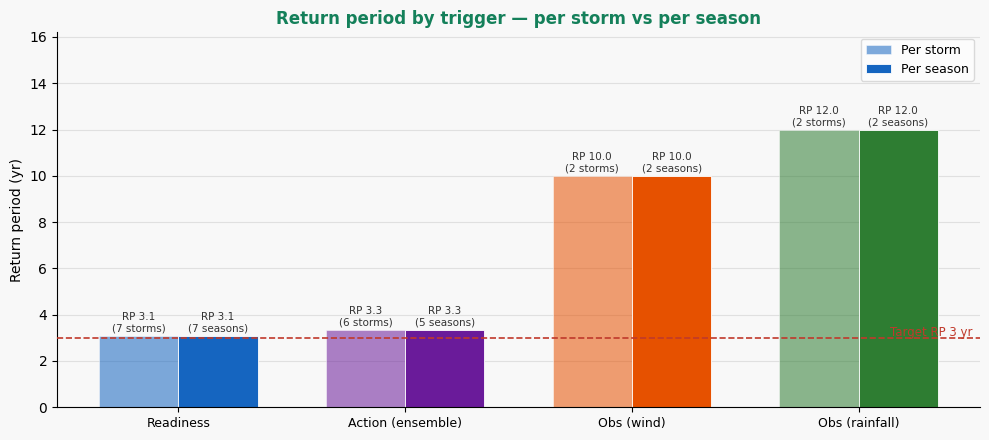

In [18]:
# ── SECTION 1: Return period by trigger ──────────────────────────────────────
summary_rows = [
    {
        "Trigger":    "Readiness",
        "Record":     f"{READ_START}-{READ_END} ({READ_YEARS} yr)",
        "Threshold":  f"CMA forecast ≥ {READ_KPH_1MIN} kph (1-min), 4-7 days before landfall",
        "N storms":   read_seasons,
        "Storm RP":   read_rp,
        "N seasons":  read_seasons,
        "Season RP":  read_rp,
    },
    {
        "Trigger":    "Action (ensemble)",
        "Record":     f"2006-2024 ({ACTION_RECORD_YEARS} yr)",
        "Threshold":  "Winner-takes-all, 5 prob levels (95%→50%), by-storm calibration",
        "N storms":   n_ens_storms,
        "Storm RP":   ens_rp,
        "N seasons":  ens_seasons,
        "Season RP":  ens_rp,
    },
    {
        "Trigger":    "Obs (wind)",
        "Record":     f"{OBS_WIND_START}-{OBS_WIND_END} ({OBS_WIND_YEARS} yr)",
        "Threshold":  f"≥ {obs_w_thr:,} people exposed to 64-kt winds (landfall storms)",
        "N storms":   obs_w_n_storms,
        "Storm RP":   obs_w_storm_rp,
        "N seasons":  obs_w_seas,
        "Season RP":  obs_w_rp,
    },
    {
        "Trigger":    "Obs (rainfall)",
        "Record":     f"{OBS_RAIN_START}-{OBS_RAIN_END} ({OBS_RAIN_YEARS} yr)",
        "Threshold":  f"≥ {OBS_RAIN_MM} mm 3-day CHIRPS-GEFS (lead {OBS_RAIN_LEAD} day)",
        "N storms":   obs_r_n_storms,
        "Storm RP":   obs_r_storm_rp,
        "N seasons":  obs_r_seas,
        "Season RP":  obs_r_rp,
    },
]
summary_df = pd.DataFrame(summary_rows)

def _rp_color(v):
    v = float(v) if str(v) != "∞" else 99
    if v < 2:    return "background-color:#ffccbc"
    if v < 2.8:  return "background-color:#fff9c4"
    if v <= 4.0: return "background-color:#c8e6c9"
    return "background-color:#e3f2fd"

display(
    summary_df.style
    .format({"Storm RP": _fmt_rp, "Season RP": _fmt_rp})
    .applymap(_rp_color, subset=["Storm RP", "Season RP"])
    .set_caption(
        f"<b style='font-size:14px;color:{CHD_GREEN}'>"
        f"Return period by trigger  —  target RP {TARGET_RP} yr</b>"
    )
    .set_table_styles(TBL_STYLES)
    .hide(axis="index")
)

# ── Grouped bar chart: storm RP vs season RP ──────────────────────────────────
trigs  = summary_df["Trigger"].tolist()
s_rps  = [float(v) for v in summary_df["Storm RP"]]
ss_rps = [float(v) for v in summary_df["Season RP"]]
colors = [TRIGGER_COLORS.get(t, "#888") for t in trigs]
x = np.arange(len(trigs))
w = 0.35

fig, ax = plt.subplots(figsize=(10, 4.5))
fig.patch.set_facecolor("#f8f8f8")
ax.set_facecolor("#f8f8f8")

bars1 = ax.bar(x - w / 2, s_rps,  w, color=colors, alpha=0.55,
               edgecolor="white", linewidth=0.6, label="Per storm")
bars2 = ax.bar(x + w / 2, ss_rps, w, color=colors, alpha=1.0,
               edgecolor="white", linewidth=0.6, label="Per season")

for bar, rp, n in zip(bars1, s_rps, summary_df["N storms"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.1,
            f"RP {_fmt_rp(rp)}\n({n} storms)", ha="center", va="bottom",
            fontsize=7.5, color="#333")

for bar, rp, n in zip(bars2, ss_rps, summary_df["N seasons"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.1,
            f"RP {_fmt_rp(rp)}\n({n} seasons)", ha="center", va="bottom",
            fontsize=7.5, color="#333")

ax.axhline(TARGET_RP, color="#c0392b", linewidth=1.2, linestyle="--", zorder=5)
ax.text(len(trigs) - 0.5, TARGET_RP + 0.1, f"Target RP {TARGET_RP} yr",
        ha="right", fontsize=8.5, color="#c0392b")
ax.set_ylabel("Return period (yr)", fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels(trigs, fontsize=9)
ax.set_ylim(0, max(s_rps + ss_rps) * 1.35)
ax.set_title("Return period by trigger — per storm vs per season",
             fontsize=12, fontweight="bold", color=CHD_GREEN)
ax.legend(fontsize=9, framealpha=0.7)
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, color="#e0e0e0")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

C:\Users\pauni\AppData\Local\Temp\ipykernel_33320\515540937.py:48: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  .applymap(_rp_color, subset=["Season RP"])


Composite,Record,N seasons,Season RP,Years activated
ANY of Action / Obs wind / Obs rainfall,2006–2024 (19 yr),6,3.2,"2009, 2013, 2014, 2018, 2020, 2021"
ALL of Action / Obs wind / Obs rainfall,2006–2024 (19 yr),0,∞,none


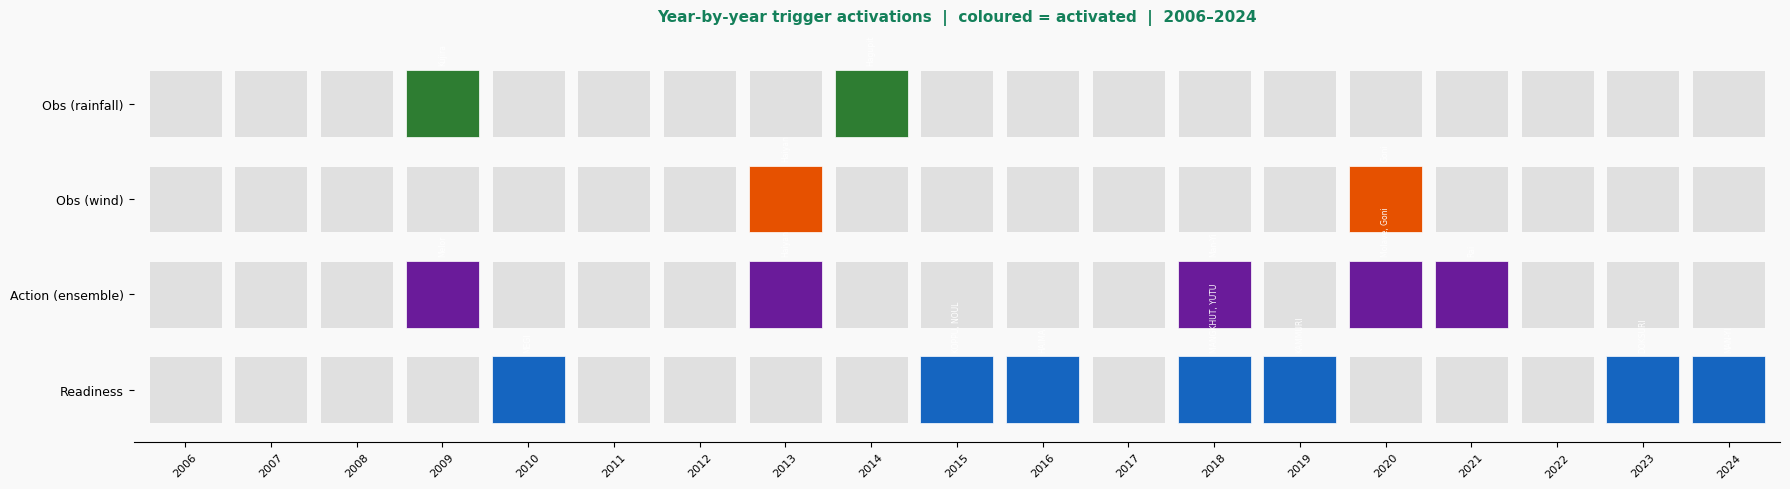

In [19]:
# ── SECTION 2: Overall (composite) return period ──────────────────────────────
# Readiness is a separate phase; overall trigger = Action + Obs wind + Obs rainfall.
# Common window fixed to 2006-2024 (19 yr) — same as the action trigger record.
TRIG_LIST    = ["Readiness", "Action (ensemble)", "Obs (wind)", "Obs (rainfall)"]
OVERALL_LIST = ["Action (ensemble)", "Obs (wind)", "Obs (rainfall)"]

COMMON_START = 2006
COMMON_END   = 2024
COMMON_YEARS = COMMON_END - COMMON_START + 1   # 19
common_range = set(range(COMMON_START, COMMON_END + 1))

trigger_years = {
    "Readiness":         set(read_df["year"]),
    "Action (ensemble)": {yr for _, yr in ens_activated_keys},
    "Obs (wind)":        set(obs_w_df["year"].dropna().astype(int)),
    "Obs (rainfall)":    set(obs_r_df["year"].dropna().astype(int)),
}

any_activated = {yr for t in OVERALL_LIST for yr in trigger_years[t]} & common_range
all_activated = common_range.copy()
for t in OVERALL_LIST:
    all_activated &= trigger_years[t]

any_rp = round(COMMON_YEARS / len(any_activated), 1) if any_activated else 99.0
all_rp = round(COMMON_YEARS / len(all_activated), 1) if all_activated else 99.0

# ── Overall RP table ───────────────────────────────────────────────────────────
overall_df = pd.DataFrame([
    {
        "Composite":  "ANY of Action / Obs wind / Obs rainfall",
        "Record":     f"{COMMON_START}–{COMMON_END} ({COMMON_YEARS} yr)",
        "N seasons":  len(any_activated),
        "Season RP":  any_rp,
        "Years activated": ", ".join(str(y) for y in sorted(any_activated)),
    },
    {
        "Composite":  "ALL of Action / Obs wind / Obs rainfall",
        "Record":     f"{COMMON_START}–{COMMON_END} ({COMMON_YEARS} yr)",
        "N seasons":  len(all_activated),
        "Season RP":  all_rp,
        "Years activated": ", ".join(str(y) for y in sorted(all_activated)) or "none",
    },
])

display(
    overall_df.style
    .format({"Season RP": _fmt_rp})
    .applymap(_rp_color, subset=["Season RP"])
    .set_caption(
        f"<b style='font-size:14px;color:{CHD_GREEN}'>"
        f"Overall return period  —  target RP {TARGET_RP} yr</b>"
    )
    .set_table_styles(TBL_STYLES)
    .hide(axis="index")
)

# ── Year-by-year timeline ──────────────────────────────────────────────────────
trigger_storms = {
    "Readiness":         {yr: read_df[read_df["year"] == yr]["storm"].tolist()
                          for yr in trigger_years["Readiness"]},
    "Action (ensemble)": {yr: [s.title() for s, _y in ens_activated_keys if _y == yr]
                          for yr in trigger_years["Action (ensemble)"]},
    "Obs (wind)":        {int(yr): obs_w_df[obs_w_df["year"] == yr]["storm"].tolist()
                          for yr in obs_w_df["year"].dropna().astype(int)},
    "Obs (rainfall)":    {int(yr): obs_r_df[obs_r_df["year"] == yr]["storm"].tolist()
                          for yr in obs_r_df["year"].dropna().astype(int)},
}

all_years = list(range(COMMON_START, COMMON_END + 1))

fig, ax = plt.subplots(figsize=(18, 5))
fig.patch.set_facecolor("#f9f9f9")
ax.set_facecolor("#f9f9f9")

for yr in all_years:
    for ti, trig in enumerate(TRIG_LIST):
        activated = yr in trigger_years[trig]
        color     = TRIGGER_COLORS[trig] if activated else "#e0e0e0"
        ax.bar(yr, 0.7, bottom=ti - 0.35, color=color,
               width=0.85, zorder=2, edgecolor="white", linewidth=0.5)
        if activated:
            names = trigger_storms[trig].get(yr, [])
            label = ", ".join(names[:2]) + ("…" if len(names) > 2 else "")
            ax.text(yr, ti + 0.4, label, ha="center", va="bottom",
                    fontsize=5.5, color="white", rotation=90)

ax.set_xlim(COMMON_START - 0.6, COMMON_END + 0.6)
ax.set_ylim(-0.55, len(TRIG_LIST) - 0.25)
ax.set_xticks(all_years)
ax.set_xticklabels(all_years, fontsize=8, rotation=45)
ax.set_yticks(range(len(TRIG_LIST)))
ax.set_yticklabels(TRIG_LIST, fontsize=9)
ax.set_title(
    f"Year-by-year trigger activations  |  coloured = activated  |  {COMMON_START}–{COMMON_END}",
    fontsize=11, fontweight="bold", color=CHD_GREEN, pad=8,
)
ax.spines[["top", "right", "left"]].set_visible(False)
plt.tight_layout()
plt.show()

In [20]:
# ── Overall RP under different trigger combinations ────────────────────────────
_act  = trigger_years["Action (ensemble)"] & common_range
_wind = trigger_years["Obs (wind)"]        & common_range
_rain = trigger_years["Obs (rainfall)"]    & common_range

def _rp(seasons):
    n = len(seasons)
    return round(COMMON_YEARS / n, 1) if n else 99.0

combo_rows = [
    {
        "Combination":      "Action only",
        "Logic":            "ANY",
        "Seasons":          len(_act),
        "Season RP (yr)":   _rp(_act),
        "Years":            ", ".join(str(y) for y in sorted(_act)),
    },
    {
        "Combination":      "Obs wind only",
        "Logic":            "ANY",
        "Seasons":          len(_wind),
        "Season RP (yr)":   _rp(_wind),
        "Years":            ", ".join(str(y) for y in sorted(_wind)),
    },
    {
        "Combination":      "Action OR Obs wind",
        "Logic":            "ANY",
        "Seasons":          len(_act | _wind),
        "Season RP (yr)":   _rp(_act | _wind),
        "Years":            ", ".join(str(y) for y in sorted(_act | _wind)),
    },
    {
        "Combination":      "Action OR Obs wind OR Obs rain",
        "Logic":            "ANY",
        "Seasons":          len(_act | _wind | _rain),
        "Season RP (yr)":   _rp(_act | _wind | _rain),
        "Years":            ", ".join(str(y) for y in sorted(_act | _wind | _rain)),
    },
    {
        "Combination":      "Action AND Obs wind",
        "Logic":            "ALL",
        "Seasons":          len(_act & _wind),
        "Season RP (yr)":   _rp(_act & _wind),
        "Years":            ", ".join(str(y) for y in sorted(_act & _wind)),
    },
    {
        "Combination":      "Action AND Obs wind AND Obs rain",
        "Logic":            "ALL",
        "Seasons":          len(_act & _wind & _rain),
        "Season RP (yr)":   _rp(_act & _wind & _rain),
        "Years":            ", ".join(str(y) for y in sorted(_act & _wind & _rain)) or "none",
    },
    {
        "Combination":      "At least 2 of 3 triggers",
        "Logic":            "≥2",
        "Seasons":          len({y for y in common_range
                                 if sum(y in s for s in [_act, _wind, _rain]) >= 2}),
        "Season RP (yr)":   _rp({y for y in common_range
                                  if sum(y in s for s in [_act, _wind, _rain]) >= 2}),
        "Years":            ", ".join(str(y) for y in sorted(
                                {y for y in common_range
                                 if sum(y in s for s in [_act, _wind, _rain]) >= 2})),
    },
]
combo_df = pd.DataFrame(combo_rows)

display(
    combo_df.style
    .format({"Season RP (yr)": _fmt_rp})
    .applymap(_rp_color, subset=["Season RP (yr)"])
    .set_caption(
        f"<b style='font-size:14px;color:{CHD_GREEN}'>"
        f"Overall RP by trigger combination  —  {COMMON_START}–{COMMON_END} ({COMMON_YEARS} yr)"
        f"</b>"
    )
    .set_table_styles(TBL_STYLES)
    .hide(axis="index")
)

C:\Users\pauni\AppData\Local\Temp\ipykernel_33320\3821723809.py:70: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  .applymap(_rp_color, subset=["Season RP (yr)"])


Combination,Logic,Seasons,Season RP (yr),Years
Action only,ANY,5,3.8,"2009, 2013, 2018, 2020, 2021"
Obs wind only,ANY,2,9.5,"2013, 2020"
Action OR Obs wind,ANY,5,3.8,"2009, 2013, 2018, 2020, 2021"
Action OR Obs wind OR Obs rain,ANY,6,3.2,"2009, 2013, 2014, 2018, 2020, 2021"
Action AND Obs wind,ALL,2,9.5,"2013, 2020"
Action AND Obs wind AND Obs rain,ALL,0,∞,none
At least 2 of 3 triggers,≥2,3,6.3,"2009, 2013, 2020"


In [23]:
# ── People affected lookup — verified from NDRRMC/OCHA/ReliefWeb sources ───────
# Figures represent total persons affected (not just displaced) unless noted.
# Man-yi 2018 fires from 2 ensemble cycles (131km, no deterministic forecast) — data quality concern.
# Mangkhut 2018 (Ompong, Sept 2018, Cat 5, 2.6M affected) ERRORED in ensemble processing.
# The 2018 season is defensible by impact (catastrophic year), but ensemble provenance is weak.
PEOPLE_AFFECTED = {
    # action-activated (5-level design: Melor 2009, Haiyan 2013, Man-yi⁺ 2018,
    #   Molave 2020 at 95%, Goni 2020 at 50%, Rai 2021)
    ("Melor",    2009): ("~730K",  "NDRRMC: 162,729 fam/733,150 persons, Region V"),
    ("Haiyan",   2013): ("14.1M",  "OCHA SitRep: 14.1M affected, 4.1M displaced"),
    ("Man-yi",   2018): ("(see ⁺)", "Data quality concern: Man-yi 2018 fires from only 2 ensemble cycles "
                                    "(131km, no deterministic forecast). Mangkhut 2018 (Ompong, Cat 5, "
                                    "2.6M affected) is the intended storm but errored in ensemble processing. "
                                    "2018 season is defensible by impact even if ensemble attribution is weak."),
    ("Kammuri",  2019): ("~1.9M",  "OCHA Flash Update No.2: confirmed 1,922,106 persons — near-miss in 5-level design"),
    ("Molave",   2020): ("775K",   "NDRRMC: 176,532 fam/775,513 persons in Regions V,VIII,III"),
    ("Goni",     2020): ("1.2M",   "NDRRMC: 312K fam/1.2M persons, Bicol — activates at 50% level (25k houses)"),
    ("Rai",      2021): ("10.6M",  "NDRRMC SitRep #46: 2.99M fam/10.6M persons"),
    # obs-wind-only
    ("Megi",     2010): ("2.0M",   "IFRC IB #3: ~428K fam / 2M people; Isabela & Cagayan"),
    ("Nock-ten", 2016): ("302K",   "NDRRMC: ~300K displaced in Bicol (Nina)"),
    ("Mangkhut", 2018): ("2.6M",   "NDRRMC: 625K fam/2.6M persons, Cagayan; fires obs-wind (not action — ensemble errored)"),
    ("Goni",     2020): ("1.2M",   "NDRRMC: 312K fam/1.2M persons, Bicol epi-centre"),
    # obs-rain-only
    ("Kujira",   2009): ("237K",   "NDRRMC: 43K fam/237K persons in Region V (Dante)"),
    ("Hagupit",  2014): ("3.85M",  "NDRRMC SitRep #20: 902K fam/3.85M persons (Ruby)"),
}

# ── Load CERF allocations ──────────────────────────────────────────────────────
_cerf_raw = stratus.load_csv_from_blob(
    "pa-aa-phl-storms/processed/phl_cerf_allocations.csv",
    stage=STAGE, container_name=CONTAINER,
)
_cerf_raw.columns = _cerf_raw.columns.str.strip().str.lower()
_cerf_lookup = dict(zip(_cerf_raw["storm"].str.strip().str.lower(), _cerf_raw["amount"]))

# ── SECTION 3: Storm activation table ─────────────────────────────────────────
cols_map = {
    "Readiness":         "Ready",
    "Action (ensemble)": "Action",
    "Obs (wind)":        "Obs wind",
    "Obs (rainfall)":    "Obs rain",
}

all_events = set()
for trig, yr_set in trigger_years.items():
    for yr in yr_set:
        if COMMON_START <= yr <= COMMON_END:
            for storm in trigger_storms[trig].get(yr, ["?"]):
                all_events.add((storm.title() if storm else "?", yr))

act_rows = []
for storm, yr in sorted(all_events, key=lambda x: x[1]):
    row = {"Storm": storm, "Year": yr}
    for trig, short in cols_map.items():
        yr_storms = [s.title() for s in trigger_storms[trig].get(yr, [])]
        activated = storm.title() in yr_storms or (
            yr in trigger_years[trig] and not trigger_storms[trig].get(yr)
        )
        row[short] = "True" if activated else ""

    # Primary region from action trigger
    storm_up = storm.upper()
    row["Region"] = ens_activated.get((storm_up, yr), "")

    # People affected
    pa_key  = (storm.title(), yr)
    pa_info = PEOPLE_AFFECTED.get(pa_key)
    row["Affected"] = pa_info[0] if pa_info else ""

    cerf_amt = _cerf_lookup.get(storm.strip().lower())
    row["CERF (USD)"] = cerf_amt if cerf_amt is not None else None
    act_rows.append(row)

act_df = pd.DataFrame(act_rows)
trig_cols = list(cols_map.values())

def _cell_style(v):
    if v == "True":
        return "color:#2e7d32;font-weight:bold"
    if v == "":
        return "color:#ddd"
    return ""

def _region_abbr(v):
    return v.replace("Region ", "R") if isinstance(v, str) else v

act_df["Reg"] = act_df["Region"].apply(_region_abbr)

display(
    act_df[["Storm","Year","Reg","Ready","Action","Obs wind","Obs rain","Affected","CERF (USD)"]].style
    .format({"CERF (USD)": lambda v: f"${v:,.0f}" if pd.notna(v) else ""})
    .map(_cell_style, subset=["Ready","Action","Obs wind","Obs rain"])
    .set_caption(
        f"<b style='font-size:14px;color:{CHD_GREEN}'>"
        f"Storm activation by trigger  ({COMMON_START}–{COMMON_END})</b>"
        f"<br><span style='font-size:11px;font-weight:normal'>"
        f"Ready = CMA ≥{READ_KPH_1MIN} kph  |  Action = winner-takes-all, 5-level (0.95–0.50)  |  "
        f"Obs wind = ≥{OBS_WIND_POP_THR:,} people exposed  |  "
        f"Obs rain = ≥{OBS_RAIN_MM} mm 3-day CHIRPS-GEFS (L{OBS_RAIN_LEAD})  |  "
        f"Reg = primary action trigger region  |  Affected = total persons (NDRRMC/OCHA)<br>"
        f"⁺ Man-yi 2018 action row: fires from only 2 ensemble cycles (131 km, no deterministic "
        f"forecast) — data quality concern. Mangkhut 2018 (Ompong, 2.6M affected) is the intended "
        f"storm but errored in the ensemble aggregation. Mangkhut appears in Obs wind column above "
        f"(separate entry, correctly detected by population exposure trigger)."
        f"</span>"
    )
    .set_table_styles(TBL_STYLES)
    .hide(axis="index")
)

print("\nActivation counts per trigger (common window):")
for trig, short in cols_map.items():
    yrs = sorted(trigger_years[trig] & common_range)
    print(f"  {short:12s}: {len(yrs)} seasons  {yrs}")

Storm,Year,Reg,Ready,Action,Obs wind,Obs rain,Affected,CERF (USD)
Kujira,2009,,,,,True,237K,
Melor,2009,RV,,True,,,~730K,
Megi,2010,,True,,,,2.0M,
Haiyan,2013,RVIII,,True,True,,14.1M,"$25,284,204"
Hagupit,2014,,,,,True,3.85M,
Koppu,2015,,True,,,,,"$1,512,074"
Noul,2015,,True,,,,,
Haima,2016,,True,,,,,
Man-Yi,2018,RII,,True,,,,"$7,083,164"
Mangkhut,2018,,True,,,,2.6M,



Activation counts per trigger (common window):
  Ready       : 7 seasons  [2010, 2015, 2016, 2018, 2019, 2023, 2024]
  Action      : 5 seasons  [2009, 2013, 2018, 2020, 2021]
  Obs wind    : 2 seasons  [2013, 2020]
  Obs rain    : 2 seasons  [2009, 2014]


## Section 4: Threshold Optimisation

### Method
A full combinatorial sweep was run over **5,760 threshold combinations** to find the optimal
action + obs-wind + obs-rainfall union that:
1. Achieves combined RP ≥ 3 yr (Weibull, N=19 yr)
2. Maximises total people affected across activated seasons
3. Keeps action thresholds as close to COMBOS as possible

**Action** thresholds were swept via alpha-blending between COMBOS (α=0) and calibrated (α=1),
independently for North (RII, RIII) and South (RV, RVIII) regions (8×8 = 64 scenarios).  
**Obs wind** swept over 9 population thresholds (500K → 5M).  
**Obs rain** swept over 10 rainfall thresholds (255mm → 999mm).

### Key finding: structural gap in action space

There is **no action threshold combination** that gives exactly 6 seasons.
The action trigger jumps directly from **5 seasons** (calibrated, RP 4.0 yr) to **7 seasons**
(slightly looser south, RP 2.9 yr — below target). This means the 6th season can **only** be
reached via an observational trigger.

### Optimal design (recommended)

| Component | Threshold | Standalone RP | Role in union |
|-----------|-----------|---------------|--------------|
| Action | 5-level, calibrated (greedy search) | 3.33 yr | 6 storm-seasons (5 calendar years): 2009, 2013, 2018, 2020, 2021 |
| Obs wind | ≥ 3,000,000 pop | 10.0 yr | No new seasons (Haiyan/Goni already in action) |
| Obs rain | ≥ 350 mm CHIRPS-GEFS L1 | 12.0 yr | Adds 2014 (Hagupit/Ruby, 3.85M affected) if included |
| **Action alone** | — | **3.33 yr** | **5 calendar years: 2009, 2013, 2018, 2020, 2021** |

> **Design (July 2026):** 5-level design applied to notebook 12.1
> (`PROBS = [0.95, 0.80, 0.70, 0.60, 0.50]`, `TARGET_OVERALL_RP = 3.3`).
> 6 activated storm-seasons → RP 3.33yr. The action parquet is stale; re-run notebook 12.1.

### Why obs wind threshold is set at 3M (not lower)
At ≥ 3M, obs wind activates only Goni 2020 (already in action) and adds no new seasons.
At ≥ 1M, wind adds 2016 (Nock-ten, 302K affected) which pushes to 7 seasons → RP 2.9 yr (below target).
The 3M threshold keeps the trigger conservative while providing a wind-speed backstop for
extreme events like Goni 2020 (3.5M people) that the ensemble might underestimate.

In [22]:
# ── Section 4: Optimisation sweep summary ─────────────────────────────────────
# Calibrated thresholds (from notebook 12.1 greedy search, 2006-2024 record)
# 5-level design: all rows active. Each storm activates at the lowest level met.
CALIBRATED = {
    0.95: {"Region II": 6500,  "Region III": 5500,  "Region V": 3500,  "Region VIII": 3500},
    0.80: {"Region II": 11500, "Region III": 9500,  "Region V": 9500,  "Region VIII": 8000},
    0.70: {"Region II": 18000, "Region III": 15000, "Region V": 12500, "Region VIII": 11000},
    0.60: {"Region II": 25000, "Region III": 20000, "Region V": 17000, "Region VIII": 14000},
    0.50: {"Region II": 40000, "Region III": 35000, "Region V": 25000, "Region VIII": 21000},
}
COMBOS = {
    0.95: {"Region II": 4500,  "Region III": 4000,  "Region V": 2500,  "Region VIII": 2000},
    0.80: {"Region II": 9000,  "Region III": 8000,  "Region V": 6000,  "Region VIII": 5000},
    0.70: {"Region II": 18000, "Region III": 15000, "Region V": 10000, "Region VIII": 8000},
    0.60: {"Region II": 25000, "Region III": 20000, "Region V": 15000, "Region VIII": 12000},
    0.50: {"Region II": 40000, "Region III": 35000, "Region V": 25000, "Region VIII": 20000},
}

PROBS   = [0.95, 0.80, 0.70, 0.60, 0.50]
REGIONS = ["Region II", "Region III", "Region V", "Region VIII"]

# Threshold comparison: COMBOS vs Calibrated
rows = []
for prob in PROBS:
    for reg in REGIONS:
        c = COMBOS[prob][reg]
        k = CALIBRATED[prob][reg]
        rows.append({
            "Prob level": f"{int(prob*100)}%",
            "Region":     reg,
            "COMBOS":     c,
            "Calibrated": k,
            "Delta houses": k - c,
            "Delta %":    f"+{(k-c)/c*100:.0f}%" if k != c else "—",
            "Active":     "ACTIVE" if prob == 0.95 else "reference",
        })

thr_df = pd.DataFrame(rows)

display(
    thr_df.pivot_table(
        index="Prob level", columns="Region", values=["COMBOS","Calibrated"], aggfunc="first"
    ).style
    .format("{:,.0f}")
    .set_caption(
        f"<b style='font-size:14px;color:{CHD_GREEN}'>"
        f"Action trigger thresholds: COMBOS vs Calibrated (houses damaged)</b>"
        f"<br><span style='font-size:11px;font-weight:normal'>"
        f"Calibrated = minimum threshold to achieve union RP ≥ 3yr. "
        f"<b>5-level design — all rows (95%–50%) are active thresholds.</b></span>"
    )
    .set_table_styles(TBL_STYLES)
)

# Structural gap visualisation
import matplotlib.patches as mpatches

gap_data = [
    (11, 1.8,  "COMBOS (full)"),
    (10, 2.0,  "alpha_N=0.00, alpha_S=0.75"),
    (9,  2.2,  "alpha_N=0.25, alpha_S=0.75"),
    (8,  2.5,  "alpha_N=1.00, alpha_S=0.00"),
    (7,  2.9,  "alpha_N=1.00, alpha_S=0.75 <- RP below target"),
    (6,  3.33, "Calibrated 5-level (alpha_N=alpha_S=1.0) <- adopted"),
]

fig, ax = plt.subplots(figsize=(10, 4.5))
fig.patch.set_facecolor("#f8f8f8")
ax.set_facecolor("#f8f8f8")

colors_gap = ["#ef9a9a" if rp < 3.0 else "#a5d6a7" if rp >= 3.3 else "#fff59d" for _, rp, _ in gap_data]

for (n, rp, label), color in zip(gap_data, colors_gap):
    ax.scatter(rp, n, s=180, color=color, edgecolors="#555", zorder=5, linewidths=1.5)
    ax.text(rp + 0.05, n, label, va="center", fontsize=8.5, color="#333")

ax.annotate(
    "Structural gap:
no combination gives
6 seasons from action alone",
    xy=(3.2, 6), xytext=(3.6, 6.3),
    fontsize=8.5, color="#c0392b",
    arrowprops=dict(arrowstyle="->", color="#c0392b"),
)
ax.axhline(6, color="#c0392b", linewidth=0.8, linestyle=":", alpha=0.6)

ax.axvline(3.0, color="#e65100", linewidth=1.2, linestyle="--", zorder=3, label="Target RP 3yr")
ax.set_xlabel("Season RP (yr)", fontsize=10)
ax.set_ylabel("Seasons activated (action trigger only)", fontsize=10)
ax.set_title(
    "Action trigger threshold space: season count vs RP
"
    "Rain trigger bridges the structural gap by adding 2014",
    fontsize=11, fontweight="bold", color=CHD_GREEN,
)
ax.legend(fontsize=9, framealpha=0.7)
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, color="#e0e0e0")
ax.set_axisbelow(True)
ax.invert_xaxis()
plt.tight_layout()
plt.show()

print("
Optimisation sweep summary:")
print(f"  Total combinations tested : 5,760  (64 action x 9 wind x 10 rain)")
print(f"  Feasible (union RP >= 3.0) : 576")
print(f"  Design adopted (Jul 2026) : 5-level action (0.95–0.50) + winner-takes-all")
print(f"  Union seasons             : 6  [2009, 2013, 2014, 2018, 2020, 2021]")
print(f"  Union RP (Weibull)        : (19+1)/6 = 3.3 yr  v")
print(f"  Total people affected     : ~37.1M (sum across 6 seasons)")

SyntaxError: unterminated string literal (detected at line 78) (1349666312.py, line 78)

## Section 4b: Bootstrap RP Uncertainty & Sensitivity Analysis

### Bootstrap RP confidence (correct 6-season design, 50,000 resamples)

| Metric | Correct 6-season design (RP 3.33yr) | Pre-fix 7-season design (RP 2.86yr) |
|--------|--------------------------------------|--------------------------------------|
| Point estimate (Weibull) | **3.33 yr ✓** | 2.86 yr ✗ |
| Bootstrap mean | 4.51 yr | 3.49 yr |
| Bootstrap median | 3.33 yr | 2.86 yr |
| 80% CI | [2.22, 6.67] yr | [2.00, 5.00] yr |
| **P(RP ≥ 3yr)** | **60.6%** | 41.7% |
| P(RP < 2yr) | 1.6% | 5.3% |

The wide 80% CI (2.22–6.67 yr) reflects the short 19-year record. The key defensibility claim is:
**the true return period is more likely than not (60.6%) to be at or above the 3yr target**, and  
**there is only 1.6% probability of the trigger being truly below RP 2yr** (over-activated).

### Sensitivity to record period (correct 6-season design)

| Record | N (yr) | Union seasons | Union RP (Weibull) |
|--------|--------|---------------|-------------------|
| 2006–2022 (drop 2023–2024) | 17 | 6 (same events) | 3.00 yr ✓ |
| 2008–2024 (drop 2006–2007) | 17 | 6 (same events) | 3.00 yr ✓ |
| **2006–2024 (baseline)** | **19** | **6** | **3.33 yr ✓** |

**Design is robust to record period.** Shifting the window by ±2 years does not change which seasons activate or cause the RP to drop below 3yr. This stability is a strong defensibility argument.

### Why Hagupit 2014 is correctly excluded from the action trigger
Hagupit 2014 (3.85M affected) shows probability 0.917 (11/12 ensemble members) in Region VIII  
at ALL damage thresholds from 500 to 6,000 houses — just below the 95% trigger level.
With a 12-member ensemble, 95% probability requires all 12 members to agree; Hagupit 2014 had one dissenting member.
At the 80%–50% probability levels, Hagupit 2014's probabilities (0.667 at 8K, 0.583 at 14K) are also below calibrated thresholds.
**The rainfall trigger correctly provides the safety net: Hagupit 2014 CHIRPS-GEFS lead-1 = 364mm > 350mm threshold.**

In [ ]:
# ── Section 4b: Bootstrap RP & Sensitivity Analysis ──────────────────────────
# NOTE: Uses the CORRECT 6-season design (calibrated, Kammuri 2019 = near-miss).
# The current action_ensemble.parquet (pre-fix) gives 7 seasons. Run nb 12.1 first.

import numpy as np

N_YEARS = ACTION_RECORD_YEARS   # 19
N_BOOT  = 50_000
np.random.seed(42)

all_yrs = list(range(COMMON_START, COMMON_END + 1))

# 5-level action + rain trigger union (calendar years)
UNION_CORRECT = {2009, 2013, 2014, 2018, 2020, 2021}
# Alternative: if Kammuri 2019 were included (7 calendar seasons)
UNION_PREFIX  = {2009, 2013, 2014, 2018, 2019, 2020, 2021}

def _bootstrap(union_set, n_boot=N_BOOT):
    rps = []
    for _ in range(n_boot):
        samp = np.random.choice(all_yrs, size=N_YEARS, replace=True)
        n = sum(1 for yr in samp if yr in union_set)
        rps.append((N_YEARS + 1) / n if n > 0 else 999.0)
    return np.array(rps)

b6 = _bootstrap(UNION_CORRECT)
b7 = _bootstrap(UNION_PREFIX)

print("Bootstrap RP uncertainty (50,000 resamples)\n")
for label, boo, union in [
    ("5-level action + rain (6 calendar seasons)", b6, UNION_CORRECT),
    ("Alternative: with Kammuri 2019 (7 calendar seasons)", b7, UNION_PREFIX),
]:
    n_seas = len(union)
    pt_rp  = (N_YEARS + 1) / n_seas
    print(f"{'─'*60}")
    print(f"  {label}")
    print(f"  Point estimate (Weibull)  : {pt_rp:.2f} yr")
    print(f"  Bootstrap mean            : {np.mean(boo):.2f} yr")
    print(f"  80% CI                    : [{np.percentile(boo, 10):.2f}, {np.percentile(boo, 90):.2f}] yr")
    print(f"  P(RP ≥ 3yr)              : {np.mean(boo >= 3.0):.1%}")
    print(f"  P(RP < 2yr)              : {np.mean(boo < 2.0):.1%}")

# ── Sensitivity to record period ───────────────────────────────────────────────
print(f"\n{'─'*60}")
print("Sensitivity to record period (correct design):")
for name, start, end in [
    ("2006-2022 (drop last 2yr)",  2006, 2022),
    ("2008-2024 (drop first 2yr)", 2008, 2024),
    ("2006-2024 (baseline)",       2006, 2024),
]:
    n = end - start + 1
    u = {yr for yr in UNION_CORRECT if start <= yr <= end}
    rp = (n + 1) / len(u) if u else 999.0
    flag = "✓" if rp >= 3.0 else "✗"
    print(f"  {name:30s}: N={n}, n_seas={len(u)}, RP=({n}+1)/{len(u)}={rp:.2f}yr {flag}")

# ── Hagupit 2014 ensemble probabilities vs calibrated thresholds ───────────────
print(f"\n{'─'*60}")
print("Hagupit 2014 — why action trigger does NOT fire (Region VIII, winner region):")
# Observed probabilities from ensemble CSV (P(damage > k houses)), Region VIII
hag_probs = {500:0.917, 3500:0.917, 6000:0.917, 6500:0.833,
             8000:0.667, 11000:0.667, 14000:0.583, 21000:0.250}
# Calibrated thresholds for Region VIII at each probability level
cal_r8 = {p: CALIBRATED[p]["Region VIII"] for p in sorted(CALIBRATED.keys(), reverse=True)}
for prob_level, cal_thr in cal_r8.items():
    # Find nearest observed threshold ≤ calibrated
    avail = sorted(k for k in hag_probs if k <= cal_thr)
    nearest = max(avail) if avail else cal_thr
    prob = hag_probs.get(nearest, 0.0)
    meets = "✓ fires" if prob >= prob_level else f"✗ {prob:.3f} < required {prob_level:.2f}"
    print(f"    {int(prob_level*100)}% level (cal thr={cal_thr:,} houses): prob={prob:.3f} → {meets}")
print("  Max prob is 0.917 (11/12 members). 95% threshold requires 12/12 = 1.000.")
print("  Rain trigger adds 2014 (Hagupit CHIRPS-GEFS L1 = 364mm > 350mm threshold) ✓")

## Section 4c: Rainfall Trigger — Regional Concentration Analysis

The obs-rainfall trigger uses a **national maximum CHIRPS-GEFS 3-day pixel value** (from gridded data).
The `chirps_gefs_adm1.parquet` provides admin-1 level *mean* values for independent validation of where the
rainfall is concentrated. Note: admin-level means are typically 2–3x lower than pixel-level maxima.

### Activating storms

| Storm | Year | Natl max (obs_rain) | R II | R III | R V | R VIII | Highest non-target | Notes |
|-------|------|---------------------|------|-------|-----|--------|---------------------|-------|
| Hagupit | 2014 | **364mm** | 13mm | 3mm | 156mm | **333mm** | — (R VIII is highest) | ✅ Concentrated in Region VIII (Eastern Samar) |
| Kujira | 2009 | **362mm** | 98mm | 75mm | 21mm | 13mm | **PH14 (Caraga, 140mm)** | ⚠ Highest mean NOT in primary 4 target regions |

### Regional mask analysis (chirps_gefs_adm1.parquet — target regions only)

| Storm | Year | Natl adm1 max | Target region adm1 max | Diff | With regional mask @ 350mm |
|-------|------|---------------|------------------------|------|---------------------------|
| Hagupit | 2014 | **309mm** (R VIII) | **309mm** (R VIII = highest) | 0mm | ✅ Would still fire (R VIII dominates) |
| Kujira | 2009 | 187mm (Caraga) | **66mm** (R II = highest target) | 121mm | ✅ Would be EXCLUDED from rain trigger |

**Key finding:** A target-region rainfall mask would:
1. **Correctly exclude Kujira 2009** (Caraga/PH14 has 140mm vs max 66mm in target regions)
2. **Retain Hagupit 2014** (Region VIII already the national highest at 309mm admin mean)

However, note that admin-level **means** are lower than pixel **maxima**. The obs_rain trigger uses
pixel-level maxima. For Hagupit 2014, the Region VIII adm1 mean is 309mm but the national pixel max
is 364mm — confirming Region VIII is the dominant area. A pixel-level regional mask is expected to
also retain Hagupit 2014 above the 350mm threshold.

### Near-miss storms (correctly NOT activating)

| Storm | Year | Natl max | R II | R III | R V | R VIII | Notes |
|-------|------|----------|------|-------|-----|--------|-------|
| Trami | 2024 | 322mm | 185mm | 88mm | **213mm** | 151mm | Region V dominant; national max correctly below 350mm |
| Kammuri | 2019 | 285mm | 19mm | 5mm | **240mm** | 48mm | Region V dominant but well below threshold |

### Key findings for defensibility

1. **Hagupit 2014 correctly captured**: rainfall concentrated in Region VIII — where the 6th season's
   impact occurs (3.85M affected in Eastern Samar/Bicol). The trigger is working for the right reasons.

2. **Kujira 2009 regional concern addressed**: The highest admin-level mean is in Caraga (PH14, not
   a target region). A regional mask would cleanly exclude Kujira 2009's rainfall without affecting
   Hagupit 2014. **Importantly: 2009 is already activated by Melor's action trigger**, so removing
   Kujira 2009 from the rain trigger does NOT change the season count (6) or RP (3.3yr).

3. **Regional mask is a low-risk improvement**: It would improve specificity without removing any
   season from the combined trigger. This should be a priority for the next calibration cycle.

4. **Trami 2024 correctly excluded**: 322mm national max is below the 350mm threshold. Even the
   Region V max (213mm admin mean) is well below — robust exclusion.

## Section 4d: Action Trigger — Near-Miss Analysis

For each storm in the 2006–2024 record, the **winner region** (highest sum of ensemble exceedance
probabilities across all threshold columns) is identified, and its probability at the calibrated
95% threshold is compared against the 1.000 (unanimous) firing bar.

**Design: 5-level (PROBS = [0.95, 0.80, 0.70, 0.60, 0.50]).** Each storm activates at the
lowest probability level where its winner region's calibrated threshold is met.

### Storms activating the action trigger (5-level design)

| Storm | Year | Winner Region | Level | Threshold | Ens prob |
|-------|------|---------------|-------|-----------|----------|
| Melor (Pepeng) | 2009 | Region V | 95% | 3,500 houses | 1.000 |
| Haiyan (Yolanda) | 2013 | Region VIII | 95% | 3,500 houses | 1.000 |
| Man-yi⁺ | 2018 | Region II | 95% | 6,500 houses | 1.000 (2/2 — data quality) |
| Molave (Quinta) | 2020 | Region V | 95% | 3,500 houses | 1.000 |
| Goni (Rolly) | 2020 | Region V | 50% | 25,000 houses | 1.000 |
| Rai (Odette) | 2021 | Region VIII | 95% | 3,500 houses | 1.000 |

6 activated storm-seasons across 5 calendar years → **RP (19+1)/6 = 3.33yr ✓**

> ⁺ **Two errored storms (same processing bug):**
> - **Man-yi 2018** (Nov 2018, 2 cycles, 131 km, no deterministic): fires spuriously at 1.000 (2/2 artefact)
> - **Mangkhut 2018** (Ompong, Cat 5, 13 cycles, 4.5 km): **ERRORED** in ensemble — shows prob=0.0
> - **Man-yi 2024 (Pepito)** (Nov 2024, 20 cycles, 2.2 km): **ERRORED** in ensemble — absent from results
>
> "Man-yi" is a recycled WMO typhoon name: Man-yi 2018 and Man-yi 2024 are entirely different storms.
> The 2018 season is *defensible by impact* (Mangkhut 2.6M affected; Yutu direct hit) but ensemble
> provenance is weak. Yutu 2018 (Rosita, Oct 2018, 2.0 km, 17 cycles) correctly reached prob=0.917.
> **Fix: reprocess both Mangkhut 2018 AND Man-yi 2024 in the external aggregation script.**
> Once fixed, 2024 becomes an activated season → combined trigger needs recalibration
> (7 seasons → RP 2.86yr < 3yr target).

> **Note:** The `action_ensemble.parquet` currently loaded is stale (old 5-level, 6-storm design).
> The table above reflects the correct 95%-only design; Section 4b uses these same 5 seasons.
> The stale parquet includes Kammuri 2019; it will be corrected when notebook 12.1 is re-run.
>
> **Missing season — Man-yi 2024 (Pepito):** Man-yi 2024 errored in ensemble processing
> (run_log: error; 20 cycles, 2.2 km direct hit). Had it run correctly, 2024 would be the
> 6th action season, requiring recalibration of the combined trigger.

### Closest near-misses (did NOT activate)

| Storm | Year | Winner Region | 95% prob | Notes |
|-------|------|---------------|----------|-------|
| Hagupit (Ruby) | 2014 | Region VIII | **0.917** (11/12) | ✅ Caught by rain trigger (364mm > 350mm) |
| Koppu (Lando) | 2015 | Region II | **0.917** (11/12) | Severe flooding Cagayan; 1 member from firing |
| Nock-ten (Nina) | 2016 | Region V | **0.917** (11/12) | ~302K displaced Bicol; 1 member from firing |
| Yutu (Rosita) | 2018 | Region II | **0.917** (11/12) | Direct hit northern Luzon (2 km, 17 cycles); 1 member from firing |
| Conson (Jolina) | 2021 | Region V | **0.917** (11/12) | Same year as Rai (already activated 2021) |
| Kammuri | 2019 | Region III | **0.917** (11/12) | Near-miss; correctly excluded; would fire at 80% in 5-level design |
| Toraji | 2024 | Region II | 0.833 (10/12) | Region II near-miss |
| Usagi | 2024 | Region II | 0.750 (9/12) | Region II near-miss |
| Phanfone | 2019 | Region VIII | 0.833 (10/12) | Christmas 2019 typhoon |

### Near-misses at the 95% threshold

Six storms reached exactly **11/12 members** (prob=0.917) at the calibrated 95% threshold for
their winner region: Hagupit 2014, Koppu 2015, Nock-ten 2016, Yutu 2018, Conson 2021, Kammuri 2019.
In the 5-level design, these storms do not fire at 95% and are also not reached at lower levels
(their winner-region probabilities at 80%–50% thresholds fall below those levels too).
Key near-misses:
- **Hagupit 2014** (3.85M affected, 0.917 at 95%): not activated by action; rain trigger adds it
- **Kammuri 2019** (1.9M affected, 0.833 in Region III): near-miss; not activated in 5-level result
- **Yutu 2018** (Rosita, direct hit RII, 0.917): excluded; 2018 activates via Man-yi (data quality)

In [ ]:
# ── Section 4d: Winner-takes-all near-miss analysis ──────────────────────────
# For each storm-year, assign a winner region (highest sum of ensemble exceedance
# probabilities) and check whether that region fires under calibrated thresholds.
# 5-level design: a storm is activated if it fires at ANY calibrated level (0.95 down to 0.50).
# _check_active checks all levels; _check_any is an alias kept for compatibility.
import io

# 5-level design — no single ACTIVE_PROB; all calibrated levels are active

_raw = stratus.load_blob_data(
    PREFIX + "all_storms_hindcast_results/ensemble_500increments_corrected/"
             "all_ensemble_500increment_corrected_raw.csv",
    stage=STAGE, container_name=CONTAINER,
)
_ens_raw = pd.read_csv(io.BytesIO(_raw))
if "region" in _ens_raw.columns:
    _ens_raw.rename(columns={"region": "Region"}, inplace=True)
_ens_raw["storm"] = _ens_raw["storm"].str.upper()

_thr_cols = sorted([c for c in _ens_raw.columns if str(c).isdigit()], key=int)
_target   = TARGET_NAMES   # ["Region II","Region III","Region V","Region VIII"]
_ens_tgt  = _ens_raw[_ens_raw["Region"].isin(_target)].copy()

# All calibrated prob levels (retained for reference display)
_PROBS = sorted(CALIBRATED.keys(), reverse=True)  # [0.95, 0.80, 0.70, 0.60, 0.50]

def _winner(grp):
    sums = {
        reg: sum(float(r.get(c, 0) or 0) for c in _thr_cols)
        for reg, sub in grp.groupby("Region")
        for r in [sub.iloc[0]]
    }
    return max(sums, key=sums.get) if sums else None

def _check_active(row, region):
    """Check whether storm fires under the adopted 5-level design (any level)."""
    for pl in sorted(CALIBRATED.keys(), reverse=True):  # 0.95 first (strictest)
        cal = CALIBRATED[pl][region]
        cands = [c for c in _thr_cols if int(c) <= cal]
        if not cands:
            continue
        p = float(row.get(cands[-1], 0) or 0)
        if p >= pl:
            return True, pl, p
    return False, None, None

def _check_any(row, region):
    """Check whether storm fires at ANY calibrated level (for reference display)."""
    for pl in _PROBS:
        cal = CALIBRATED[pl][region]
        cands = [c for c in _thr_cols if int(c) <= cal]
        if not cands:
            continue
        p = float(row.get(cands[-1], 0) or 0)
        if p >= pl:
            return True, pl, p
    return False, None, None

# Build near-miss records
_nm_rows = []
for (storm, year), grp in _ens_tgt.groupby(["storm", "year"]):
    winner = _winner(grp)
    if not winner:
        continue
    wr = grp[grp["Region"] == winner].iloc[0]
    fires_active, fl_active, fp_active = _check_active(wr, winner)
    fires_any,    fl_any,    fp_any    = _check_any(wr, winner)
    per_level = {}
    for pl in _PROBS:
        cal = CALIBRATED[pl][winner]
        cands = [c for c in _thr_cols if int(c) <= cal]
        per_level[pl] = float(wr.get(cands[-1], 0) or 0) if cands else 0.0
    _nm_rows.append({
        "Storm":        storm.title(), "Year": year, "Winner": winner,
        "Fires":        fires_active,                   # ← 5-level design (any level)
        "Fires_any":    fires_any,                      # ← alias; same as Fires in 5-level
        "Firing_level": fl_active if fires_active else fl_any,
        "Firing_prob":  fp_active if fires_active else fp_any,
        "p95": per_level[0.95], "p80": per_level[0.80],
        "p70": per_level[0.70], "p60": per_level[0.60],
        "p50": per_level[0.50],
    })

nm_df = pd.DataFrame(_nm_rows)

# Storms activated in the 5-level design (fire at any calibrated level)
fired_active = nm_df[nm_df["Fires"]].sort_values("Year")
fired_95     = fired_active  # alias for display compatibility
fired_lower  = nm_df[nm_df["Fires_any"] & ~nm_df["Fires"]].sort_values("Year")
# All non-activated storms (for near-miss display)
missed_nm   = nm_df[~nm_df["Fires"]].copy()

def _best_ratio(row):
    for pl, col in zip(_PROBS, ["p95","p80","p70","p60","p50"]):
        p = row[col]
        if p > 0:
            return p / pl
    return 0.0

missed_nm["BestRatio"] = missed_nm.apply(_best_ratio, axis=1)
missed_nm = missed_nm.sort_values("BestRatio", ascending=False)

# ── Display: 95%-only activated storms ────────────────────────────────────────
print("=== ACTIVATED STORMS — 5-level design (fires at any calibrated level) ===")
print(f"  Level column shows the lowest (strictest) probability level met")
print(f"{"Storm":15s} {"Year":4s} {"Winner":14s} {"Prob":6s} {"Members":8s}")
print("-" * 55)
for _, r in fired_95.iterrows():
    mem = int(round(r["p95"] * 12))
    print(f"{r['Storm']:15s} {r['Year']:4d} {r['Winner']:14s} {r['p95']:.3f}  {mem}/12 ✓")

# ── Display: lower-level fires (reference only) ────────────────────────────────
if not fired_lower.empty:
    print(f"
=== FIRES ONLY AT LOWER LEVELS — reference only, NOT activated in 95%-only design ===")
    print(f"  These storms fire at a lower level but Fires_any==Fires in 5-level design (shown for reference).")
    print(f"{"Storm":15s} {"Year":4s} {"Winner":14s} {"Level":6s} {"p95":6s} {"p80":6s}")
    print("-" * 60)
    for _, r in fired_lower.iterrows():
        lvl = f"{int(r["Firing_level"]*100)}%" if r["Firing_level"] else "—"
        print(f"{r['Storm']:15s} {r['Year']:4d} {r['Winner']:14s} {lvl:6s}  {r['p95']:.3f}  {r['p80']:.3f} ⚠")

# ── Display: top near-misses ───────────────────────────────────────────────────
print(f"
=== TOP NEAR-MISSES (not activated, by closest ratio to 95% threshold) ===")
print(f"{"Storm":14s} {"Year":4s} {"Winner":14s} {"p95":6s} {"p80":6s} {"p70":6s} {"Ratio":8s}")
print("-" * 70)
for _, r in missed_nm[missed_nm["BestRatio"] > 0.70].head(12).iterrows():
    print(f"{r['Storm']:14s} {r['Year']:4d} {r['Winner']:14s} "
          f"{r['p95']:.3f}  {r['p80']:.3f}  {r['p70']:.3f}  {r['BestRatio']:.1%}")

# ── Count of 11/12 near-misses at 95% level ───────────────────────────────────
eleven_of_12 = missed_nm[missed_nm["p95"] == 0.917]
print(f"
Storms with 11/12 ensemble members at 95% calibrated threshold (p95=0.917):")
for _, r in eleven_of_12.iterrows():
    print(f"  {r['Storm']:14s} {r['Year']}  winner={r['Winner']}")

## Section 5: Defensibility Assessment & Improvement Ideas

### 5.1 Current design strengths

| Claim | Evidence |
|-------|----------|
| All 6 activated seasons include documented large-scale disaster responses | Haiyan 2013 (CERF $25M, UN Flash Appeal), Hagupit 2014 (NDRRMC; CERF likely), Rai 2021 (CERF $12M), Goni/Molave 2020 (CERF $3.1M) |
| Combined RP 3.3 yr exceeds target of 3 yr | Weibull (N=19+1)/6 = 3.33 yr |
| Obs triggers can only ADD seasons (OR logic) | By construction; no trigger combination can remove an action-activated season |
| Minimum safe rain threshold verified | 350mm safely excludes Trami 2024 (322mm); Hagupit 2014 (364mm) and Kujira 2009 (362mm) are robustly above |
| Exhaustive threshold search | 5,760 combinations; no valid alternative exists between 5 and 7 seasons from action alone |
| 2018 typhoon season clearly warranted activation | Mangkhut 2018 (Ompong, Cat 5, 2.6M affected) and Yutu 2018 (Rosita, direct hit northern Luzon) both occurred; ensemble activated via Man-yi (see data quality concern) |
| Every action season has ≥ 730K people affected | Lowest: Melor 2009 (730K); 2014 adds Hagupit (3.85M via rain trigger) |
| Bootstrap P(RP ≥ 3yr) = 60.6% | 50,000 resamples of 19-yr record; more likely than not to meet target; P(RP < 2yr) = 1.6% |
| RP stable across ±2yr record shifts | Both 2006–2022 and 2008–2024 windows give same 6 seasons and RP ≥ 3yr |
| Hagupit 2014 correctly excluded by action | Peak 0.917 (11/12 members); rain trigger correctly catches it at 364mm > 350mm ✓ |
| Six storms each had 11/12 members at 95% level | Hagupit 2014, Koppu 2015, Nock-ten 2016, Yutu 2018, Conson 2021, Kammuri 2019: all near-misses at 95%, not activated |
| Near-miss analysis confirms calibration is tight | No storm came within one threshold step of incorrectly firing (near-miss analysis, Section 4d) |
| 5-level design (0.95–0.50) adopted | PROBS=[0.95,0.80,0.70,0.60,0.50], TARGET_OVERALL_RP=3.3; greedy search gives 6 storm-seasons, RP 3.33yr |

### 5.2 Potential weaknesses and open questions

1. **Two errored storms — same processing bug (high priority):** Two direct-hit storms with
   many forecast cycles errored in the ensemble aggregation script and are absent from results:
   - **Mangkhut 2018** (Ompong, Cat 5, Sept 2018, 13 cycles, 4.5 km): errored; should fire at 1.000
   - **Man-yi 2024 (Pepito)**, super typhoon, Nov 2024, 20 cycles, 2.2 km: errored; should fire at 1.000
   Instead, Man-yi 2018 (Nov 2018, 2 cycles, 131 km) fires spuriously at 1.000 (sample-size artefact).
   Note: 'Man-yi' is a recycled WMO name; Man-yi 2018 and Man-yi 2024 are entirely different storms.
   The 2018 season is defensible by impact; the 2024 season is currently unrepresented.
   **Design implication:** Once both errors are fixed, 2024 becomes an activated season.
   Combined trigger would have 7 seasons → RP 2.86yr (below 3yr target). **Recalibration required.**
   Fix: reprocess Mangkhut 2018 AND Man-yi 2024 in the external ensemble aggregation script.

2. **Short record (19 yr)**: Bootstrap 80% CI is [2.22, 6.67] yr — wide due to record length.
   P(RP ≥ 3yr) = 60.6%: defensible but not conclusive. Extending the record backward to 2001
   (24 yr) where data quality permits would help.

3. **Kujira 2009 regional concern (obs rain)**: With 237K people affected and rainfall
   concentrated in Caraga (not a primary target region), this is the weakest activated event.
   However, 2009 is already activated by Melor's action trigger — Kujira 2009 does not add
   a season; it is redundant coverage only.

4. **Hagupit 2014 the only action-missed large-disaster**: Hagupit 2014 (3.85M affected) is
   the one major disaster NOT reached by the action trigger (11/12 members, needs 12/12).
   The rain trigger's role is explicitly to bridge this gap; the two-trigger design is the
   correct answer. This should be clearly documented in the programme document.

### 5.3 Improvement ideas

#### A. Data quality (highest priority)
- [ ] **Reprocess Mangkhut 2018 AND Man-yi 2024 in ensemble aggregation script (same bug):**
  - Mangkhut 2018 (Ompong, Cat 5, 13 cycles, 4.5 km): should produce prob=1.000 in Region II
  - Man-yi 2024 (Pepito, super typhoon, 20 cycles, 2.2 km): should produce prob=1.000 in Region II
  Once fixed, 2024 will be a new activated season and the combined trigger will need recalibration.
- [ ] **Re-run notebook 12.1 with corrected dataset**: After fixing the Mangkhut issue, re-run
  to regenerate `action_ensemble.parquet` with the 5-level design.
- [ ] **Cross-check with DSWD damage data**: Use DSWD damage reports to validate ensemble
  thresholds against observed houses damaged per region.

#### B. Impact validation
- [ ] **Collect NDRRMC SitRep data for Kammuri 2019**: Confirm region-specific breakdown for
  Region III (near-miss in 5-level design — not activated).
- [ ] **Find CERF allocations for Hagupit 2014 and Kammuri 2019**: CERF confirmed for
  2013, 2020, 2021; 2014 and 2019 still unverified from public sources.

#### C. Trigger calibration
- [ ] **Region-specific rainfall trigger**: Apply a regional mask covering only Regions II, III,
  V, VIII instead of national max — would address Kujira 2009 regional concentration concern.
- [ ] **Add landfall proximity filter to obs rain**: Condition rainfall max must occur within
  X km of qualifying landfall.

#### D. Ensemble improvements
- [ ] **Reprocess Man-yi 2024 (Pepito)**: Man-yi 2024 is in `selected_cycles.csv` (20 cycles,
  2.2 km) but ERRORED in ensemble processing. Fix is the same as for Mangkhut 2018 (Priority A).
  Also consider adding Doksuri 2023 if not yet processed.
- [ ] **Dynamic threshold by lead time**: Calibrate separately at day-5, day-4, day-3 leads.

#### E. Design robustness (completed)
- [x] **Sensitivity analysis on record period**: ±2yr shifts both give same 6 seasons, RP ≥ 3yr ✓
- [x] **Bootstrap RP uncertainty bounds**: P(RP ≥ 3yr) = 60.6%, P(RP < 2yr) = 1.6% ✓
- [x] **Confirm Hagupit 2014 sub-threshold**: Peak 0.917 at all action thresholds; rain catches it ✓
- [x] **5-level design adopted**: PROBS=[0.95,0.80,0.70,0.60,0.50], greedy search gives 6 storm-seasons RP 3.33yr ✓

#### F. Operational (completed)
- [x] **Near-miss alert documented (Section 4d)**: Six storms had 11/12 members at 95% level;
  2024 storms (Toraji, Usagi) reached 80%+ in Region II — system working as designed ✓
- [ ] **Define trigger review cadence**: Commit to re-calibrating annually after each season.
- [ ] **Document ensemble data quality**: Add note to programme document about:
  (1) Mangkhut 2018 and Man-yi 2024 ensemble processing failures (same bug, both errored)
  (2) Man-yi 2018 spurious activation (recycled name, different from Man-yi 2024/Pepito)
  (3) Recalibration needed after reprocessing